<a href="https://colab.research.google.com/github/kashis93/Food-delivery-time-prediction-model/blob/main/Food_delivery_time_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
#  always import this libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df=pd.read_csv('/content/drive/MyDrive/food delivery/train.csv/train.csv')

In [6]:
df.head(10)

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30
5,0x9bb4,HYDRES09DEL03,22,4.8,17.431668,78.408321,17.461668,78.438321,11-03-2022,21:20:00,21:30:00,conditions Cloudy,Jam,0,Buffet,motorcycle,1,No,Urban,(min) 26
6,0x95b4,RANCHIRES15DEL01,33,4.7,23.369746,85.339820,23.479746,85.449820,04-03-2022,19:15:00,19:30:00,conditions Fog,Jam,1,Meal,scooter,1,No,Metropolitian,(min) 40
7,0x9eb2,MYSRES15DEL02,35,4.6,12.352058,76.606650,12.482058,76.736650,14-03-2022,17:25:00,17:30:00,conditions Cloudy,Medium,2,Meal,motorcycle,1,No,Metropolitian,(min) 32
8,0x1102,HYDRES05DEL02,22,4.8,17.433809,78.386744,17.563809,78.516744,20-03-2022,20:55:00,21:05:00,conditions Stormy,Jam,0,Buffet,motorcycle,1,No,Metropolitian,(min) 34
9,0xcdcd,DEHRES17DEL01,36,4.2,30.327968,78.046106,30.397968,78.116106,12-02-2022,21:55:00,22:10:00,conditions Fog,Jam,2,Snack,motorcycle,3,No,Metropolitian,(min) 46


In [7]:
df.shape

(45593, 20)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          45593 non-null  object 
 3   Delivery_person_Ratings      45593 non-null  object 
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  45593 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            45593 non-null  object 
 12  Road_traffic_density         45593 non-null  object 
 13  Vehicle_conditio

In [9]:
df['Delivery_person_Age']

,Delivery_person_Age
0,37
1,34
2,23
3,38
4,32
...,...
45588,30
45589,21
45590,30
45591,20


In [10]:
df['Delivery_person_Age'][0]

'37'

In [11]:
type(df['Delivery_person_Age'][0])

str

In [12]:
df['Weatherconditions']

,Weatherconditions
0,conditions Sunny
1,conditions Stormy
2,conditions Sandstorms
3,conditions Sunny
4,conditions Cloudy
...,...
45588,conditions Windy
45589,conditions Windy
45590,conditions Cloudy
45591,conditions Cloudy


In [13]:
df['Weatherconditions'] = df['Weatherconditions'].apply(lambda temp: temp.split(" ")[1] if pd.notnull(temp) and " " in str(temp) else temp)

In [14]:
df['Weatherconditions']

,Weatherconditions
0,Sunny
1,Stormy
2,Sandstorms
3,Sunny
4,Cloudy
...,...
45588,Windy
45589,Windy
45590,Cloudy
45591,Cloudy


In [15]:
df['Weatherconditions'].value_counts()

,count
Weatherconditions,
Fog,7654
Stormy,7586
Cloudy,7536
Sandstorms,7495
Windy,7422
Sunny,7284
NaN,616


In [16]:
df['Weatherconditions']=='conditions NaN'

,Weatherconditions
0,False
1,False
2,False
3,False
4,False
...,...
45588,False
45589,False
45590,False
45591,False


In [17]:
df[df['Weatherconditions']=='conditions NaN']

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)


In [18]:
df.columns

Index(['ID', 'Delivery_person_ID', 'Delivery_person_Age',
       'Delivery_person_Ratings', 'Restaurant_latitude',
       'Restaurant_longitude', 'Delivery_location_latitude',
       'Delivery_location_longitude', 'Order_Date', 'Time_Orderd',
       'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density',
       'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle',
       'multiple_deliveries', 'Festival', 'City', 'Time_taken(min)'],
      dtype='object')

In [19]:
df.select_dtypes(include='object')

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,19-03-2022,11:30:00,11:45:00,Sunny,High,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,25-03-2022,19:45:00,19:50:00,Stormy,Jam,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,19-03-2022,08:30:00,08:45:00,Sandstorms,Low,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,05-04-2022,18:00:00,18:10:00,Sunny,Medium,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,26-03-2022,13:30:00,13:45:00,Cloudy,High,Snack,scooter,1,No,Metropolitian,(min) 30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45588,0x7c09,JAPRES04DEL01,30,4.8,24-03-2022,11:35:00,11:45:00,Windy,High,Meal,motorcycle,0,No,Metropolitian,(min) 32
45589,0xd641,AGRRES16DEL01,21,4.6,16-02-2022,19:55:00,20:10:00,Windy,Jam,Buffet,motorcycle,1,No,Metropolitian,(min) 36
45590,0x4f8d,CHENRES08DEL03,30,4.9,11-03-2022,23:50:00,00:05:00,Cloudy,Low,Drinks,scooter,0,No,Metropolitian,(min) 16
45591,0x5eee,COIMBRES11DEL01,20,4.7,07-03-2022,13:35:00,13:40:00,Cloudy,High,Snack,motorcycle,1,No,Metropolitian,(min) 26


In [20]:
df.select_dtypes(include='object').columns

Index(['ID', 'Delivery_person_ID', 'Delivery_person_Age',
       'Delivery_person_Ratings', 'Order_Date', 'Time_Orderd',
       'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density',
       'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival',
       'City', 'Time_taken(min)'],
      dtype='object')

In [21]:
df.select_dtypes(include='object')

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,19-03-2022,11:30:00,11:45:00,Sunny,High,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,25-03-2022,19:45:00,19:50:00,Stormy,Jam,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,19-03-2022,08:30:00,08:45:00,Sandstorms,Low,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,05-04-2022,18:00:00,18:10:00,Sunny,Medium,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,26-03-2022,13:30:00,13:45:00,Cloudy,High,Snack,scooter,1,No,Metropolitian,(min) 30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45588,0x7c09,JAPRES04DEL01,30,4.8,24-03-2022,11:35:00,11:45:00,Windy,High,Meal,motorcycle,0,No,Metropolitian,(min) 32
45589,0xd641,AGRRES16DEL01,21,4.6,16-02-2022,19:55:00,20:10:00,Windy,Jam,Buffet,motorcycle,1,No,Metropolitian,(min) 36
45590,0x4f8d,CHENRES08DEL03,30,4.9,11-03-2022,23:50:00,00:05:00,Cloudy,Low,Drinks,scooter,0,No,Metropolitian,(min) 16
45591,0x5eee,COIMBRES11DEL01,20,4.7,07-03-2022,13:35:00,13:40:00,Cloudy,High,Snack,motorcycle,1,No,Metropolitian,(min) 26


In [22]:
 '''Basic data cleaning we need to do like
 1.fix free text formatting quirks like 'condition sunny'👉 'sunny'   remove unnnecessary condition word for clear filtering
 2. In null value it is showing NaN means not null value but it does not contains any value so we have to
    replace it with real pandas recognized null
 3.strip stay white space from each text columns
 4.convert numerical looking text column to actual number like time taken from (min)36 👉 36 so
   it can handle betterlyas it is object but we can convert into number
 5.impute missing value (median for skewed numerics ,mode for categorical)
   when we find missing value we can do 2 things
          1) we can remove that entire rows
          2) we can replace any value in that missing value to match all
6.find the duplicate value remove entire duplicate row or that value '''


"Basic data cleaning we need to do like\n1.fix free text formatting quirks like 'condition sunny'👉 'sunny'   remove unnnecessary condition word for clear filtering\n2. In null value it is showing NaN means not null value but it does not contains any value so we have to\n   replace it with real pandas recognized null\n3.strip stay white space from each text columns\n4.convert numerical looking text column to actual number like time taken from (min)36 👉 36 so\n  it can handle betterlyas it is object but we can convert into number\n5.impute missing value (median for skewed numerics ,mode for categorical)\n  when we find missing value we can do 2 things\n         1) we can remove that entire rows\n         2) we can replace any value in that missing value to match all\n6.find the duplicate value remove entire duplicate row or that value "

In [23]:
for col in df.select_dtypes(include='object').columns:
 df[col]=df[col].str.strip()
 df[col]=df[col].replace('NaN',np.nan)

In [24]:
df[df['Weatherconditions']=='NaN']

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)


In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          43739 non-null  object 
 3   Delivery_person_Ratings      43685 non-null  object 
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  43862 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            44977 non-null  object 
 12  Road_traffic_density         44992 non-null  object 
 13  Vehicle_conditio

In [26]:
df['Time_taken(min)'][0]

'(min) 24'

In [27]:
type(df['Time_taken(min)'][0])

str

In [28]:
temp='(min) 24'

In [29]:
df['Time_taken(min)'] = df['Time_taken(min)'].apply(lambda temp: int(temp.split(" ")[1]) if pd.notnull(temp)  else temp)

In [30]:
type(df['Time_taken(min)'][0])

numpy.int64

In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          43739 non-null  object 
 3   Delivery_person_Ratings      43685 non-null  object 
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  43862 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            44977 non-null  object 
 12  Road_traffic_density         44992 non-null  object 
 13  Vehicle_conditio

In [32]:
for col in ['Delivery_person_Age','Delivery_person_Ratings','multiple_deliveries']:
  df[col]=pd.to_numeric(df[col],errors='coerce')

In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          43739 non-null  float64
 3   Delivery_person_Ratings      43685 non-null  float64
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  43862 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            44977 non-null  object 
 12  Road_traffic_density         44992 non-null  object 
 13  Vehicle_conditio

In [34]:
df.describe()

,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Vehicle_condition,multiple_deliveries,Time_taken(min)
count,43739.000000,43685.000000,45593.000000,45593.000000,45593.000000,45593.000000,45593.000000,44600.000000,45593.000000
mean,29.567137,4.633780,17.017729,70.231332,17.465186,70.845702,1.023359,0.744664,26.294607
std,5.815155,0.334716,8.185109,22.883647,7.335122,21.118812,0.839065,0.572473,9.383806
min,15.000000,1.000000,-30.905562,-88.366217,0.010000,0.010000,0.000000,0.000000,10.000000
25%,25.000000,4.500000,12.933284,73.170000,12.988453,73.280000,0.000000,0.000000,19.000000
50%,30.000000,4.700000,18.546947,75.898497,18.633934,76.002574,1.000000,1.000000,26.000000
75%,35.000000,4.900000,22.728163,78.044095,22.785049,78.107044,2.000000,1.000000,32.000000
max,50.000000,6.000000,30.914057,88.433452,31.054057,88.563452,3.000000,3.000000,54.000000


In [35]:
df['Delivery_person_Ratings']<5

,Delivery_person_Ratings
0,True
1,True
2,True
3,True
4,True
...,...
45588,True
45589,True
45590,True
45591,True


In [36]:
df[df['Delivery_person_Ratings']>5]['Delivery_person_Ratings']

,Delivery_person_Ratings
3586,6.0
4714,6.0
5169,6.0
5362,6.0
5651,6.0
6394,6.0
7031,6.0
7681,6.0
9499,6.0
9535,6.0


In [37]:
df['Delivery_person_Ratings']=df['Delivery_person_Ratings'].clip(upper=5)

In [38]:
df.describe()

,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Vehicle_condition,multiple_deliveries,Time_taken(min)
count,43739.000000,43685.000000,45593.000000,45593.000000,45593.000000,45593.000000,45593.000000,44600.000000,45593.000000
mean,29.567137,4.632567,17.017729,70.231332,17.465186,70.845702,1.023359,0.744664,26.294607
std,5.815155,0.331560,8.185109,22.883647,7.335122,21.118812,0.839065,0.572473,9.383806
min,15.000000,1.000000,-30.905562,-88.366217,0.010000,0.010000,0.000000,0.000000,10.000000
25%,25.000000,4.500000,12.933284,73.170000,12.988453,73.280000,0.000000,0.000000,19.000000
50%,30.000000,4.700000,18.546947,75.898497,18.633934,76.002574,1.000000,1.000000,26.000000
75%,35.000000,4.900000,22.728163,78.044095,22.785049,78.107044,2.000000,1.000000,32.000000
max,50.000000,5.000000,30.914057,88.433452,31.054057,88.563452,3.000000,3.000000,54.000000


In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          43739 non-null  float64
 3   Delivery_person_Ratings      43685 non-null  float64
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  43862 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            44977 non-null  object 
 12  Road_traffic_density         44992 non-null  object 
 13  Vehicle_conditio

In [40]:
#fill missing numerical (skewed value) with median( robust to outier/skew)

for col in ['Delivery_person_Age','Delivery_person_Ratings','multiple_deliveries']:
  df[col].fillna(df[col].median(),inplace=True)

/tmp/ipykernel_952/466700635.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(),inplace=True)


In [41]:
# fill missing categorical value with mode (most frequent use)
for col in ['Weatherconditions','Road_traffic_density','City','Festival']:
  df[col].fillna(df[col].mode()[0],inplace=True)

/tmp/ipykernel_952/915791926.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mode()[0],inplace=True)


In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          45593 non-null  float64
 3   Delivery_person_Ratings      45593 non-null  float64
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  43862 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            45593 non-null  object 
 12  Road_traffic_density         45593 non-null  object 
 13  Vehicle_conditio

In [43]:
df.describe()

,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Vehicle_condition,multiple_deliveries,Time_taken(min)
count,45593.000000,45593.000000,45593.000000,45593.000000,45593.000000,45593.000000,45593.000000,45593.000000,45593.000000
mean,29.584739,4.635389,17.017729,70.231332,17.465186,70.845702,1.023359,0.750225,26.294607
std,5.696333,0.324828,8.185109,22.883647,7.335122,21.118812,0.839065,0.567430,9.383806
min,15.000000,1.000000,-30.905562,-88.366217,0.010000,0.010000,0.000000,0.000000,10.000000
25%,25.000000,4.600000,12.933284,73.170000,12.988453,73.280000,0.000000,0.000000,19.000000
50%,30.000000,4.700000,18.546947,75.898497,18.633934,76.002574,1.000000,1.000000,26.000000
75%,34.000000,4.800000,22.728163,78.044095,22.785049,78.107044,2.000000,1.000000,32.000000
max,50.000000,5.000000,30.914057,88.433452,31.054057,88.563452,3.000000,3.000000,54.000000


EDA


In [44]:
df['Time_taken(min)'].describe()

,Time_taken(min)
count,45593.000000
mean,26.294607
std,9.383806
min,10.000000
25%,19.000000
50%,26.000000
75%,32.000000
max,54.000000


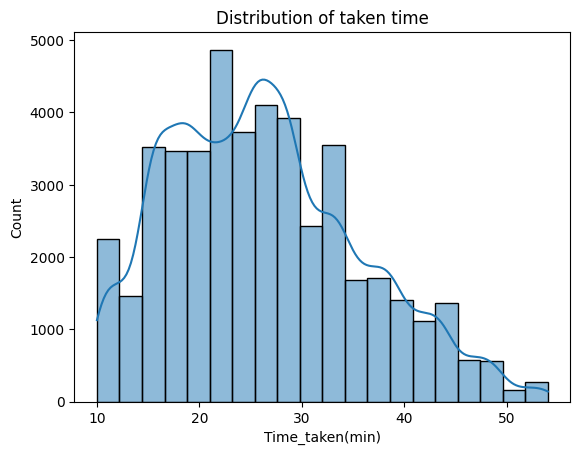

In [45]:
sns.histplot(df['Time_taken(min)'],bins=20,kde=True)
plt.title('Distribution of taken time')
plt.show()

In [46]:
df['Road_traffic_density'].value_counts()

,count
Road_traffic_density,
Low,16078
Jam,14143
Medium,10947
High,4425


In [47]:
df.groupby('Road_traffic_density')['Time_taken(min)'].agg(['count','mean','median','std'])

,count,mean,median,std
Road_traffic_density,,,,
High,4425,27.240000,27.0,8.396012
Jam,14143,31.176624,31.0,9.940904
Low,16078,21.464175,21.0,6.988438
Medium,10947,26.699644,27.0,8.560179


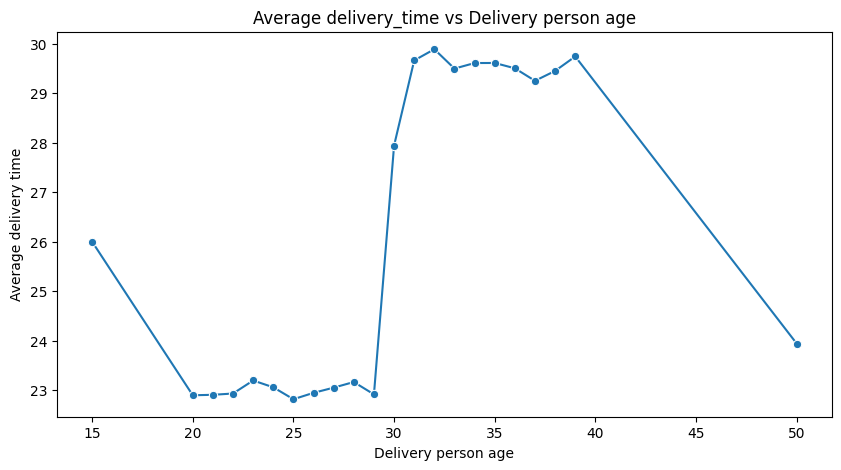

In [48]:
plt.figure(figsize=(10,5))
sns.lineplot(data=df,
             x="Delivery_person_Age",
             y="Time_taken(min)",
             estimator="mean",
             errorbar=None,
             marker="o")
plt.title("Average delivery_time vs Delivery person age")
plt.xlabel("Delivery person age")
plt.ylabel("Average delivery time")
plt.show()

In [49]:
df[df['Delivery_person_Ratings']<4].shape[0]/len(df)

0.02998267277871603

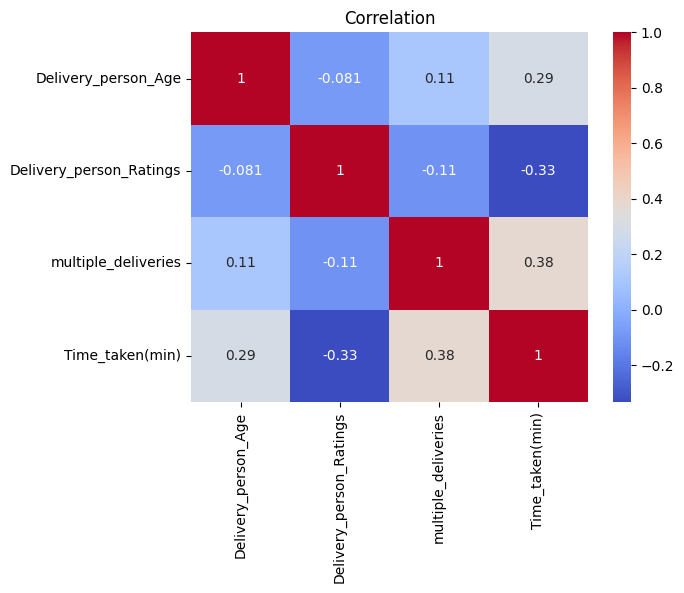

In [50]:
numerical_cols=['Delivery_person_Age','Delivery_person_Ratings','multiple_deliveries','Time_taken(min)']
sns.heatmap(df[numerical_cols].corr(),annot=True,cmap="coolwarm")
plt.title("Correlation")
plt.show()

In [51]:
def calculate_series_distance(
    lat1_series, lon1_series, lat2_series, lon2_series, miles=False
):
    """Calculates the great-circle (straight-line) distance between two series of
    lat/lon points using the Haversine formula. Returns distance in km (or
    miles). Turns four raw coordinate columns into one meaningful 'distance'
    feature.
    """
    r = 3956 if miles else 6371

    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1_series, lon1_series, lat2_series, lon2_series]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )

    c = 2 * np.arcsin(np.sqrt(a))

    return c * r

In [52]:
df['distance_km']=calculate_series_distance(df['Restaurant_latitude'],df['Restaurant_longitude'],df['Delivery_location_latitude'],df['Delivery_location_longitude'])

In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          45593 non-null  float64
 3   Delivery_person_Ratings      45593 non-null  float64
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  43862 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            45593 non-null  object 
 12  Road_traffic_density         45593 non-null  object 
 13  Vehicle_conditio

In [54]:
df=df[df['distance_km']<100].reset_index(drop=True)

In [55]:
# Hour of day the order was placed (0–23) — kept continuous, not binned
df['order_hour'] = pd.to_datetime(
    df['Time_Orderd'],
    format='%H:%M:%S',
    errors='coerce'
).dt.hour

In [56]:
# A handful of unparseable timestamps become NaN hours — fill with median hour
df['order_hour'].fillna(df['order_hour'].median(), inplace=True)


/tmp/ipykernel_952/2264237044.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['order_hour'].fillna(df['order_hour'].median(), inplace=True)


In [57]:
# Convert Order_Date to datetime first, then find the weekend indicator
df['order_date_dt'] = pd.to_datetime(df['Order_Date'], format='%d-%m-%Y')
df['is_weekend'] = df['order_date_dt'].dt.dayofweek.isin([5, 6]).astype(int)

In [58]:
df.groupby('is_weekend')['Time_taken(min)'].agg(['mean', 'median', 'std'])

,mean,median,std
is_weekend,,,
0,26.316796,26.0,9.390559
1,26.248632,25.0,9.365927


In [59]:
df.drop(columns=['is_weekend'], inplace=True)

In [60]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45162 entries, 0 to 45161
Data columns (total 23 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   ID                           45162 non-null  object        
 1   Delivery_person_ID           45162 non-null  object        
 2   Delivery_person_Age          45162 non-null  float64       
 3   Delivery_person_Ratings      45162 non-null  float64       
 4   Restaurant_latitude          45162 non-null  float64       
 5   Restaurant_longitude         45162 non-null  float64       
 6   Delivery_location_latitude   45162 non-null  float64       
 7   Delivery_location_longitude  45162 non-null  float64       
 8   Order_Date                   45162 non-null  object        
 9   Time_Orderd                  43706 non-null  object        
 10  Time_Order_picked            45162 non-null  object        
 11  Weatherconditions            45162 non-nu

Encoding(machine learning odel only understand numerical balue so we convert the categorical into numerical value


In [61]:
# there are 2 type of encoding one hot(nomainal encoding) and ordial encoding where in nominal no natural order
# so in nominal like vehical jsut devide the column into serval binary column like is_bike,is_car,is_scooty
# in ordinal like traffic assign value be ranking like high traffic=3,medium=2,low=1

traffic_mapping={
    'Low':0,
    'Medium':1,
    'High':2,
    'Jam':3
}
df['Road_traffic_density']=df['Road_traffic_density'].map(traffic_mapping)


In [62]:
df['Road_traffic_density']

,Road_traffic_density
0,2
1,3
2,0
3,1
4,2
...,...
45157,2
45158,3
45159,0
45160,2


In [63]:
# Define X from your dataframe df (dropping ID and the target variable)
features_to_drop = ['ID', 'Delivery_person_ID', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'order_date_dt', 'Time_taken(min)']
X = df.drop(columns=features_to_drop, errors='ignore')

# Apply one-hot nominal encoding using pd.get_dummies with corrected column names
X = pd.get_dummies(X, columns=['Type_of_order', 'Type_of_vehicle', 'Festival', 'City', 'Weatherconditions'], drop_first=True, dtype=int)

dataset spliting skllearn model o train and test datset

In [64]:
from sklearn.model_selection import train_test_split

In [65]:
# Define the target variable y
y = df['Time_taken(min)']

# Perform train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [66]:
X_train.shape,X_test.shape,y_train.shape,y_test.shape

((36129, 25), (9033, 25), (36129,), (9033,))

standarlizing to each numerical column in between fixed range for mean 0 and standa deviation 1 we apply for both linear and tree based model once as the tree model not required although

In [67]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()


In [68]:
#fit the scaler on the train never on test
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)


In [69]:
# as it is in numpy array we can convert it back into dataframe like
# to the original column name and index
X_train_scaled=pd.DataFrame(X_train_scaled,columns=X_train.columns,index=X_train.index)
X_test_scaled=pd.DataFrame(X_test_scaled,columns=X_test.columns,index=X_test.index)


In [70]:
import joblib
# save the fited sacler
joblib.dump(scaler,'scaler.pkl')


['scaler.pkl']

**Model 1 Linear Regression**fits best fit straight line for all features simplest base line project

In [71]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score


In [72]:
lr=LinearRegression()

In [73]:
lr.fit(X_train_scaled,y_train)

LinearRegression()

In [74]:
lr.coef_

array([ 2.25758443e+00, -2.17731142e+00,  6.94483977e+05, -2.00978593e+06,
       -6.94613614e+05,  2.00979719e+06,  2.92028414e+00, -1.73602503e+00,
        1.71909395e+00,  5.84836125e+00, -5.46508641e-01, -7.05326392e-02,
       -2.62372891e-02, -1.60280502e-02, -4.47720704e-01, -9.85909371e-01,
       -1.22686419e+00,  1.33069898e+00,  5.84333957e-01, -8.09834772e-01,
        8.39655865e-02, -1.00564437e+00, -1.01046650e+00, -2.31274350e+00,
       -9.68503039e-01])

In [75]:
X_train.columns

Index(['Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude',
       'Restaurant_longitude', 'Delivery_location_latitude',
       'Delivery_location_longitude', 'Road_traffic_density',
       'Vehicle_condition', 'multiple_deliveries', 'distance_km', 'order_hour',
       'Type_of_order_Drinks', 'Type_of_order_Meal', 'Type_of_order_Snack',
       'Type_of_vehicle_electric_scooter', 'Type_of_vehicle_motorcycle',
       'Type_of_vehicle_scooter', 'Festival_Yes', 'City_Semi-Urban',
       'City_Urban', 'Weatherconditions_Fog', 'Weatherconditions_Sandstorms',
       'Weatherconditions_Stormy', 'Weatherconditions_Sunny',
       'Weatherconditions_Windy'],
      dtype='object')

In [76]:
y_predication=lr.predict(X_test_scaled)

In [77]:
rmse_test=np.sqrt(mean_squared_error(y_test,y_predication))

In [78]:
rmse_train=np.sqrt(mean_squared_error(y_train,lr.predict(X_train_scaled)))

In [79]:
r2_test=r2_score(y_test,y_predication)

In [80]:
r2_train=r2_score(y_train,lr.predict(X_train_scaled))

In [81]:
print(rmse_train,r2_train)

6.0430685553035035 0.5834066568018113


In [82]:
rmse_test = np.sqrt(mean_squared_error(y_test, y_predication))
print(rmse_test, r2_test)

6.2124031997602716 0.569330407124212


# **Model-2 Decision Tree**


In [83]:
from sklearn.tree import DecisionTreeRegressor

In [84]:
dt=DecisionTreeRegressor()


In [85]:
dt.fit(X_train_scaled,y_train)

DecisionTreeRegressor()

In [86]:
y_Pred_dt=dt.predict(X_test_scaled)

In [87]:
#test performance
from sklearn.metrics import mean_squared_error,r2_score
rmse_test=np.sqrt(mean_squared_error(y_test,y_Pred_dt))
r2_test=r2_score(y_test,y_Pred_dt)
print(rmse_test,r2_test)

5.384918112226985 0.6764188998814586


In [88]:
#now  check train performance for comparsion ths is how we catch overfitting
rmse_train=np.sqrt(mean_squared_error(y_train,dt.predict(X_train_scaled)))
r2_train=r2_score(y_train,dt.predict(X_train_scaled))
print(rmse_train,r2_train)

0.0 1.0


# **MOdel 3 Random forest**

In [89]:
from sklearn.ensemble import RandomForestRegressor

In [90]:
rf=RandomForestRegressor(n_estimators=100,random_state=42)

In [91]:
rf.fit(X_train_scaled,y_train)

RandomForestRegressor(random_state=42)

In [92]:
from sklearn.metrics import mean_squared_error,r2_score
mse=mean_squared_error(y_test,rf.predict(X_test_scaled))
rmse=np.sqrt(mse)
r2=r2_score(y_test,rf.predict(X_test_scaled))
print(rmse,r2)

4.029902465622597 0.8187767099052841


In [93]:
from sklearn.metrics import mean_squared_error,r2_score
mse=mean_squared_error(y_train,rf.predict(X_train_scaled))
rmse=np.sqrt(mse)
r2=r2_score(y_train,rf.predict(X_train_scaled))
print(rmse,r2)

1.5114012871911553 0.9739410531975997


In [94]:
#Tuning --randomized search overthe tree depth/features cheaper than full grid search over this mANY HYPERPARAMETERS

In [95]:
from sklearn.model_selection import RandomizedSearchCV

rf_param_grid = {
    'n_estimators': [200, 300, 400, 500],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['auto', 'sqrt', 'log2', 0.5]
}

# Corrected: Pass rf only once via the estimator parameter
rf_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=rf_param_grid,
    n_iter=25,
    cv=3,
    verbose=2,
    n_jobs=-1,
    scoring='r2',
    random_state=42
)

rf_search.fit(X_train_scaled, y_train)
print("best_params", rf_search.best_params_)
print("best_score", rf_search.best_score_)
rf_best = rf_search.best_estimator_

Fitting 3 folds for each of 25 candidates, totalling 75 fits


KeyboardInterrupt: 

In [ ]:
r2_rf_tuned=r2_score(y_test,rf_best.predict(X_test_scaled))
rmse_rf_tuned=np.sqrt(mean_squared_error(y_test,rf_best.predict(X_test_scaled)))
print(r2_rf_tuned,rmse_rf_tuned)

In [ ]:
#on which features the forest actualy leans on
rf.feature_importances_

In [ ]:
X_train.columns

# **Model 4 XgBoost**







In [96]:
from xgboost import XGBRegressor

In [97]:
xgb=XGBRegressor(n_estimators=100,random_state=42)

In [98]:
xgb.fit(X_train_scaled,y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=None, num_parallel_tree=None, ...)

In [99]:
from sklearn.metrics import mean_absolute_error , mean_squared_error,r2_score
mse=mean_squared_error(y_test,xgb.predict(X_test_scaled))
rmse=np.sqrt(mse)
r2=r2_score(y_test,xgb.predict(X_test_scaled))
print(rmse,r2)

4.003996045105893 0.8210992217063904


In [101]:
xgb_param_grid = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 4, 5],
    'subsample': [0.8, 0.9, 1.0],
    'colsample_bytree': [0.8, 0.9, 1.0],
    'reg_alpha': [0, 0.1, 0.5],
    'reg_lambda': [0, 0.1, 0.5]
}
xgb.search = RandomizedSearchCV(
    estimator=XGBRegressor(random_state=42),
    param_distributions=xgb_param_grid,
    n_iter=25,
    cv=3,
    verbose=2,
    n_jobs=-1,
    scoring='r2',
    random_state=42
)
xgb.search.fit(X_train_scaled, y_train)
print("best_params", xgb.search.best_params_)
print("best_score", xgb.search.best_score_)

Fitting 3 folds for each of 25 candidates, totalling 75 fits
best_params {'subsample': 1.0, 'reg_lambda': 0.5, 'reg_alpha': 0, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.2, 'colsample_bytree': 1.0}
best_score 0.808565080165863


In [102]:
r2_xgb_train=r2_score(y_train,xgb.predict(X_train_scaled))
rmse_xgb_train=np.sqrt(mean_squared_error(y_train,xgb.predict(X_train_scaled)))
print(r2_xgb_train,rmse_xgb_train)

0.8642541170120239 3.4495676626682035


In [103]:
r2_xgb_test=r2_score(y_test,xgb.predict(X_test_scaled))
rmse_xgb_test=np.sqrt(mean_squared_error(y_test,xgb.predict(X_test_scaled)))
print(r2_xgb_test,rmse_xgb_test)

0.8210992217063904 4.003996045105893


In [104]:
X_test_scaled.shape

(9033, 25)

In [105]:
#test adjusted r2
y_test_pred=xgb.predict(X_test_scaled)
n_test=len(y_test)
p_test=X_test_scaled.shape[1]
adjusted_r2_test=1-(1-r2_score(y_test,y_test_pred))*(n_test-1)/(n_test-p_test-1)
print("adjusted r2",adjusted_r2_test)

adjusted r2 0.820602661313658


In [111]:
def order_period(hour):
  if 12<=hour<=14:
    return "lunch"
  elif 19<=hour<=21:
    return "dinner"
  else:
    return "normal"

In [112]:
#1.copy unscaled data
x_train_exp=X_train.copy()
x_test_exp=X_test.copy()

In [113]:
#2. create new feature before scalling
x_train_exp['order_period']=x_train_exp['order_hour'].apply(order_period)
x_test_exp['order_period']=x_test_exp['order_hour'].apply(order_period)


In [115]:
x_train_exp['order_hour']

,order_hour
24844,17.0
33010,21.0
16599,21.0
35248,11.0
14293,8.0
...,...
11284,21.0
44732,23.0
38158,13.0
860,8.0


In [109]:
#3 one hot encoding
x_train_exp=pd.get_dummies(x_train_exp,columns=['order_period'],drop_first=True,dtype=int)
x_test_exp=pd.get_dummies(x_test_exp,columns=['order_period'],drop_first=True,dtype=int)

In [117]:
#4 create new scaler and fit only on expanded training data
# Drop the original string column 'order_period' before scaling
if 'order_period' in x_train_exp.columns:
    x_train_exp = x_train_exp.drop(columns=['order_period'])
if 'order_period' in x_test_exp.columns:
    x_test_exp = x_test_exp.drop(columns=['order_period'])

scaler_exp=StandardScaler()
x_train_exp_scaled=scaler_exp.fit_transform(x_train_exp)
x_test_exp_scaled=scaler_exp.transform(x_test_exp)

In [118]:
xgb_with_period=XGBRegressor(n_estimators=100,random_state=42)
xgb_with_period.fit(x_train_exp_scaled,y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=None, num_parallel_tree=None, ...)

In [119]:
n_test=x_test_exp_scaled.shape[0]
p_test=x_test_exp_scaled.shape[1]
r2_with_period_test=r2_score(y_test,xgb_with_period.predict(x_test_exp_scaled))
adjusted_r2_with_period_test=1-(1-r2_with_period_test)*(n_test-1)/(n_test-p_test-1)
print(r2_with_period_test,adjusted_r2_with_period_test)

0.8210992217063904 0.820602661313658


In [121]:
# Save the best-performing XGBoost model found during hyperparameter tuning
xgb_best = xgb.search.best_estimator_
joblib.dump(xgb_best, 'xgb_best.pkl')

['xgb_best.pkl']

In [122]:
model=joblib.load('/content/xgb_best.pkl')
scaler=joblib.load('/content/scaler.pkl')

In [125]:
sample=X_test[0:3]

In [126]:
sample_scaled=scaler.transform(sample)

In [127]:
predictions=model.predict(sample_scaled)

In [128]:
predictions

array([42.52784 , 18.987696, 37.706867], dtype=float32)

In [129]:
y_test[0:3]

,Time_taken(min)
29851,46
32062,19
25859,40


Coefficent of determination